### Resistor Shadowing Functions examples

this is a encapsulated notebook to show how to use the shadowing functions

the resistor may block some light on entrance or exit. We need to account for that. We model the insensitive area as a rectangle with width ff that surrounds the SPAD. We assume light is incident on a plane perpendicular to a SPAD edge wall.

I have formulated the problem two ways. '''Absolute''' and '''Relative''' meaning we use the absolute geometries (pitch, ff, h) or we use the relative geometries (W = ff/pitch, H = h/pitch)

- $FF_o$ = fill factor in relative units (0 to 1), at zero incidence, as reported by manufacturer
- $p$ or $pp$ = SPAD pitch
- $l$ = length of shadowing caused by resistor

__absolute units:__
- $ff$ = fill factor width, absolute units
- $h$ = height of resistor

__relative units:__
- $H = h/p$ = relative height of resistor to spad size
- $W = ff/p$ = relative width of insensitive area to spad pitch

---
### Calculating $ff, W$ from $FF_o$
The normal fill factor is just the ratio of the areas of the squares:
$$FF_o = \frac{(p-2ff)^2}{p^2}$$

Expanding:
$$FF_o = 1 - \frac{4ff}{p} + \frac{4ff^2}{p^2}$$
$$0 = ff^2 - pff + p^2(1 - FF_o)/4$$
$$ax^2 + bx + c = 0$$

Solve using quadratic formula, the minimum solution is the physical one. See function __ff_from_FF__

can also divide by $p^2$ to get in relative units $W = ff/p$:
$$FF_o = 4W^2 - 4W + 1$$
$$0 = W^2 - W + (1 - FF_o)/4$$

---
#### Calculating $FF(\theta)$

For something of height $h$ subtended at an angle $\theta$ from normal, the shadowing will have a length $l$ given by:
$$l = h \cdot \tan(\theta)$$

So now we can easily calculate the fill factor at angle $\theta$, as the ratio of the sensitive area (rectangle) to the total area (square), for __transmission__:
$$FF(\theta) = \frac{(p - 2ff)(p - 2ff - l)}{p^2}$$

For __reflectivity__, the shadowing happends on the way in and out:
$$FF(\theta)_R = \frac{(p - 2ff)(p - 2ff - \mathbf{2}l)}{p^2}$$

Left as an exercise to the reader, in relative units this becomes:
$$FF(\theta) = FF_o - (1 - 2W)H \tan(\theta)$$
$$FF(\theta)_R = FF_o - \mathbf{2}(1 - 2W)H \tan(\theta)$$

It is hard to make do this in a 'relative' way, because the effect depends on the FF, and all the data I have been analyzing has some absolute meaning.

---
### Modified PDE

PDE becomes:
$$PDE(\theta) = FF(\theta) \cdot T(\theta) \cdot iPDE$$

Under our previous assumptions, the specular reflectivity becomes:
$$R_{SiPM}(\theta) = FF(\theta)_R \cdot R(\theta)$$

---
### Biasing Bernoulli trials (or not)
Because we do diffuse using $FF_o$, you should not apply shadowing prior to diffuse/specular decision. Apply the shadowing to R, T from the lookup tables AFTER the diffuse/specular decision has been made. Then you get A = 1 - R - T as a consequence.

In [2]:
#### Possible inputs ####

## for HPK VUV4
pp = 50  # pitch in microns
FFo = 0.6  # fill factor
h_hpk = 2.5 # height in microns

## for FBK VUVHD3 (we dont see shadowing on this device lol)
# FFo = 0.8
# pp = 35 # pitch in microns (not sure)

In [3]:
import numpy as np
deg2rad = np.pi/180

### solving for ff, W ###
def quadraticSolution(a, b, c):
  return (-b + np.sqrt(b**2 - 4*a*c))/(2*a), (-b - np.sqrt(b**2 - 4*a*c))/(2*a)

# this returns the relative size of the microstructure width wrt pitch
def W_from_FF(FF):
  sol = quadraticSolution(1, -1, (1-FF)/4)
  return min(sol)

def FF_from_W(W):
  return 4*(W**2) - 4*W + 1

# this returns the absolute width of the microstructure
# this is the same as above, multiplied by pitch
def ff_from_FF(FF, pitch):
  sol = quadraticSolution(1, -1, (1-FF)/4)
  return min(sol) * pitch
  
### Shadowing functions ###
## these all take in angles in degrees.

def l_loss(h, theta): # theta in degrees, h in absolute height
  theta = np.abs(theta * deg2rad)
  return h * np.tan(theta)

def FF_theta_absolute(p, ff, h, theta):
  l = l_loss(h, theta)
  top1 = p - 2*ff
  top2 = p - 2*ff - l
  return (top1 * top2)/(p**2)

def FF_theta_absolute_Ref(p, ff, h, theta):
  l = l_loss(h, theta)
  top1 = p - 2*ff
  top2 = p - 2*ff - 2*l
  return (top1 * top2)/(p**2)

# only the subtracting part of the FF(theta) equation
# (for doing reflectivity where we subtract shadow twice)
def FF_theta_relative_shadow(theta, W, H):
  theta= np.abs(theta * deg2rad)
  return (1 - 2*W)*H*np.tan(theta)

def FF_theta_relative(theta, W, H):
  # W defined as ff/p
  # H defined as h/p
  return FF_from_W(W) - FF_theta_relative_shadow(theta, W, H)

def FF_theta_relative_Ref(theta, W, H):
  return FF_from_W(W) - 2*FF_theta_relative_shadow(theta, W, H)

## check they all close ##
testW = W_from_FF(0.6)
testff = ff_from_FF(FF=0.6, pitch=50)

testFF = FF_theta_absolute(p=50, ff=testff, h=4.5, theta=40)
testFF_rel = 0.6 - FF_theta_relative_shadow(theta=40, W=testW, H=4.5/50)
t2 = FF_theta_relative(theta=40, W=testW, H=4.5/50)

print(testFF, testFF_rel, t2)

0.541503259847549 0.541503259847549 0.5415032598475491


In [4]:
### Test Functions for R and T curves ###

def R_test(theta, R0=0.5, power=2.0):
  """
  Simple reflectivity function that increases with angle
  R(theta) = R0 * (1 + (theta/90)^power)
  
  Parameters:
  - theta: angle in degrees
  - R0: reflectivity at normal incidence
  - power: controls how quickly R increases with angle
  """
  theta = np.abs(theta)
  normalized_angle = theta / 90.0  # normalize to 0-1 range
  return R0 * (1 + normalized_angle**power)

def T_test(theta):
  return 1 - R_test(theta)

this is for HPK device with parameters:
FFo = 0.6, pitch = 50 microns
Shadowing methods agree within 0.001 tolerance: T=True, R=True


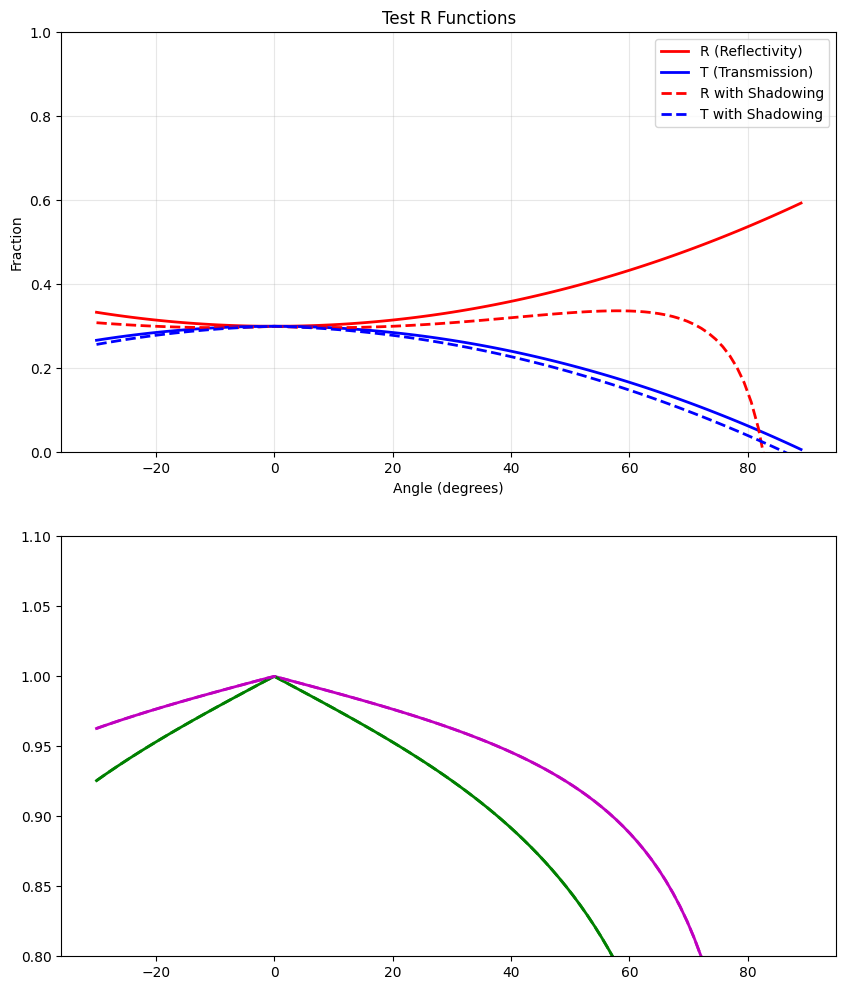

In [15]:
import matplotlib.pyplot as plt

angles = np.linspace(-30, 89, 100)

# Calculate R and T for all angles
R_values = FFo * R_test(angles)
T_values = FFo * T_test(angles)

print("this is for HPK device with parameters:")
print(f"FFo = {FFo}, pitch = {pp} microns")

## define your parameters
ff = ff_from_FF(FFo, pp)
W = W_from_FF(FFo)
H = h_hpk / pp

## calculate the shadowing however you like
shadowT_a = FF_theta_absolute(pp, ff, h_hpk, angles)
shadowT_b = FF_theta_relative(angles, W, H)

shadowR_a = FF_theta_absolute_Ref(pp, ff, h_hpk, angles)
shadowR_b = FF_theta_relative_Ref(angles, W, H)

# Check if both methods for shadowing agree within a tolerance of 0.001
agree_T = np.allclose(shadowT_a, shadowT_b, atol=0.001)
agree_R = np.allclose(shadowR_a, shadowR_b, atol=0.001)
print(f"Shadowing methods agree within 0.001 tolerance: T={agree_T}, R={agree_R}")

R_s = shadowR_a * R_test(angles)
T_s = shadowT_a * T_test(angles)

###### plotting ######
# Plot the results
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12))

ax2.plot(angles, shadowR_a/FFo, 'g-', label='Shadow R Abs', linewidth=2)
ax2.plot(angles, shadowT_a/FFo, 'm-', label='Shadow T Abs', linewidth=2)
ax2.plot(angles, shadowR_b/FFo, 'g--', label='Shadow R Rel', linewidth=2)
ax2.plot(angles, shadowT_b/FFo, 'm--', label='Shadow T Rel', linewidth=2)

ax1.plot(angles, R_values, 'r-', label='R (Reflectivity)', linewidth=2)
ax1.plot(angles, T_values, 'b-', label='T (Transmission)', linewidth=2)

ax1.plot(angles, R_s, 'r--', label='R with Shadowing', linewidth=2)
ax1.plot(angles, T_s, 'b--', label='T with Shadowing', linewidth=2)

ax1.set_xlabel('Angle (degrees)')
ax1.set_ylabel('Fraction')
ax1.set_title('Test R Functions')
ax1.legend()

# ax2.set_xlabel('Angle (degrees)')
# ax2.set_ylabel('Fraction')
# ax2.set_title('Test T Functions')
# ax2.legend()

ax1.grid(True, alpha=0.3)
# plt.xlim(0, 90)
ax1.set_ylim(0, 1)

ax2.set_ylim(0.8, 1.1)
plt.show()

In [6]:
## so very simply, for use in chroma:

# you need pitch, FF and resistor height
# 1. do your normal bernoulli trial with FFo
# 2. then apply shadowing to R and T separately using the above equations
# 2a. absolute: supply FF, pitch, height
# 2b. relative: supply W, H (W = ff/pitch, H = h/pitch)
# 3. multiply T and R by shadowing factors
# 4. do you normal R, T trials, now R + T < 1.0, do absorption when needed
# 5. profit